# Predicting when an engine needs maintenance
### NASA C-MAPSS · Applied machine learning

**22.63-cycle test RMSE — 31.7% below our previous best model.**

A controlled study of 709 training engines across four operating/fault scenarios.
The reported test model uses regime-normalized sensor histories and XGBoost with a
150-cycle training target cap. Evaluation uses the true, uncapped remaining life
of 707 test engines.

**Main finding:** the model improves prediction within the maintenance planning
window. The cap sacrifices accuracy for some engines much earlier in life.

**Development follow-up:** a 50-cycle TCN improves primary CV RMSE to
23.59–24.13 versus 25.93 for XGBoost on the same development endpoints. It has
not received a new audit or official-test evaluation (Section 12).

*Presentation guide:* read the sections in order. Code is available for inspection;
training runs and full comparisons are retained in the supporting notebooks.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'outputs/experiments/results.json').exists(): ROOT=ROOT/'nasa-rul'
sys.path.insert(0,str(ROOT/'scripts'))
EXP=ROOT/'outputs/experiments'
ROB=ROOT/'outputs/robustness'
OUT=ROOT/'outputs/presentation'
r=json.loads((EXP/'results.json').read_text())
metrics=pd.read_csv(EXP/'test_metrics.csv')
comparison=pd.read_csv(EXP/'experiment_comparison.csv')
audit=pd.read_csv(EXP/'audit_metrics.csv')
sensor_audit=pd.read_csv(OUT/'sensor_audit.csv')
sensor_results=json.loads((OUT/'sensor_results.json').read_text())
plt.rcParams.update({'figure.figsize':(10,4.8),'font.size':12,'axes.titlesize':15,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.labelcolor':'#25344a','text.color':'#172b4d'})
COLORS={'Original XGBoost':'#637b96','Random Forest':'#9aabc0','Final XGBoost':'#087f8c'}

## 1. The decision: inspect now, or keep operating?

Estimate **remaining useful life (RUL)** from measurements available at the
current cycle. Then flag engines whose estimated remaining life is short enough
to justify an inspection.

- **Prediction target:** operational cycles remaining until failure.
- **Illustrative maintenance event:** actual RUL ≤30 cycles.
- **Evaluation:** prediction error, missed events and false alerts.

A missed event can delay inspection; a false alert can prompt unnecessary work.
No cost data are provided, so we do not claim financial savings or deployment readiness.

## 2. The evidence: four datasets, all available engines

Each row contains one engine-cycle observation: three operating settings and
21 sensor measurements. Training histories run to failure; test histories stop
earlier. Engine identifiers are scoped by dataset to prevent histories from mixing.

In [2]:
data=pd.read_csv(EXP/'data_audit.csv')
table=data.pivot(index='dataset',columns='split',values='engines').reindex(['FD001','FD002','FD003','FD004'])
table=table.rename(columns={'train':'Training engines','test':'Test engines'})
table['Operating conditions']=[1,6,1,6]
table['Fault modes']=[1,1,2,2]
display(table[['Training engines','Test engines','Operating conditions','Fault modes']].rename_axis(index=None,columns=None))

,Training engines,Test engines,Operating conditions,Fault modes
FD001,100,100,1,1
FD002,260,259,6,1
FD003,100,100,1,2
FD004,249,248,6,2


**160,359 training observations; 104,897 test observations.** Input hashes and engine/cycle keys checked.

**Data checks matter.** The actual FD004 files contain 249 training and 248 test
engines; the bundled README reverses these counts. We use verified file contents.
There are no missing or non-finite measurements in these inputs. Extreme values
are retained because they can reflect operating conditions or degradation.

Source: local NASA C-MAPSS archive, with provenance and hashes in `data/source.json`.
These are simulations, not evidence of performance on a real fleet.

## 3. A fair comparison: keep engines separate

**567 development engines** → **three-fold engine CV** → **freeze model and alert rule**

Then evaluate **142 untouched audit engines**, refit on all **709 training engines**,
and evaluate the **707 official test engines**.

We compare three synthetic observation points per engine:

- **Primary protocol:** true RUL between 1 and 200 cycles, with at least 20 observed cycles.
- **Broad protocol:** observation points across the engine lifetime, including earlier life.

Every engine contributes equal endpoint weight. Normalization and feature filtering
are learned inside each training fold. Earlier features cannot use future measurements.

**Scope:** the 200-cycle planning window is an explicit assumption. Previous test
results motivated this work, so the official test is not a newly blind benchmark.

## 4. Are all 21 sensors useful?

**All 21 are read; only 17 sensor channels reach the final fitted model.**

The fitted variance filter removes sensors **1, 5, 18 and 19**, including all their
history features. That leaves **127 inputs**: 119 sensor-derived features plus
cycle, three settings and four dataset indicators.

Sensors **6, 10 and 16** have low variation and low model importance, but they
are not constant across every dataset. Variation is not proof of predictive value;
we tested removal rather than relying on a universal sensor blacklist.

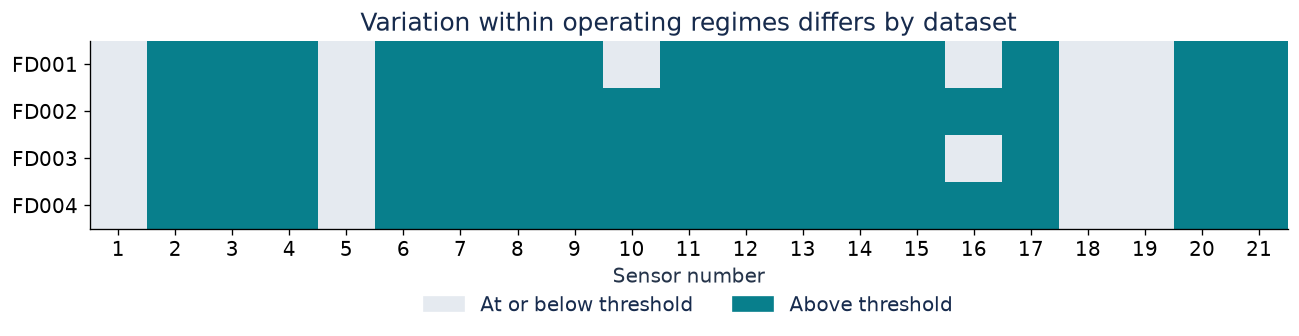

In [3]:
order=[f'sensor_{i}' for i in range(1,22)]
variation=sensor_audit.pivot(index='dataset',columns='sensor',values='max_within_regime_std')[order]
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots(figsize=(11,3.2))
ax.imshow(variation.gt(1e-6).to_numpy(),cmap=ListedColormap(['#e5eaf0','#087f8c']),vmin=0,vmax=1,aspect='auto')
ax.set(xticks=np.arange(21),xticklabels=np.arange(1,22),yticks=np.arange(4),yticklabels=variation.index,
       xlabel='Sensor number',title='Variation within operating regimes differs by dataset')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#e5eaf0',label='At or below threshold'),Patch(color='#087f8c',label='Above threshold')],
          loc='upper center',bbox_to_anchor=(.5,-.26),ncol=2,frameon=False)
fig.tight_layout()
plt.show()

The chart uses a within-regime standard deviation threshold of 10⁻⁶ in source
units. It describes variation, **not a ranking of sensor usefulness**.

In [4]:
sensor_comparison=pd.read_csv(OUT/'sensor_ablation.csv')
display(sensor_comparison.pivot(index='model',columns='protocol',values='RMSE')
        .rename(columns={'primary':'Primary CV RMSE','broad':'Broad CV RMSE'}).rename_axis(index=None,columns=None).round(3))

,Broad CV RMSE,Primary CV RMSE
Current model: 17 retained sensors,45.317,25.932
Reduced model: 14 sensors,45.216,25.958


**Sensor decision:** dropping 6, 10 and 16 as well gives **25.958** primary CV RMSE,
versus **25.932** with 17 sensors. The difference is tiny and reverses on broad
validation; it does not establish a meaningful advantage for either set.

We retain the existing 17-sensor final model. The 14-sensor comparison used the
same 567 development engines and endpoints; no new official test tuning was done.
A simpler model may be attractive, but this ablation alone does not justify
calling the three sensors useless.

## 5. What changed in the winning pipeline?

1. **Normalize sensors by operating regime**, using fitting engines only.
2. **Build causal history features:** five- and twenty-cycle means, variability,
   recent slopes, exponentially weighted means and one-cycle changes.
3. **Cap training RUL at 150 cycles**, reducing the need to distinguish very long
   remaining lifetimes. Validation and test labels remain uncapped.
4. **Fit XGBoost:** depth 6, 800 trees, learning rate 0.03.

Cycle remains a feature. Engine weighting, separate dataset models, cycle removal
and asymmetric loss were tested but did not win the declared selection criterion.
The 21-configuration study is a bounded comparison, not an exhaustive search.

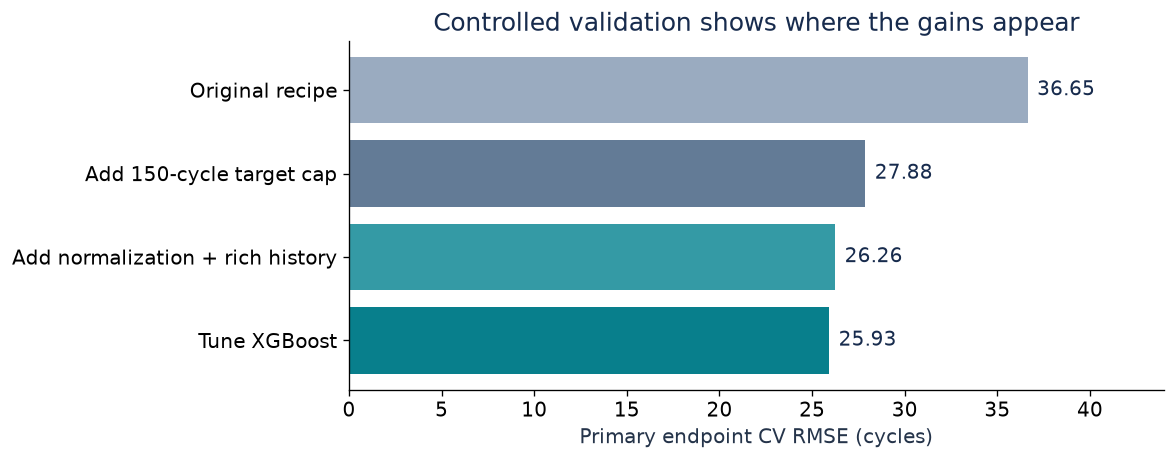

In [5]:
chosen=['reference_raw_uncapped','raw_cap150','rich_cap150','tuned_d6_n800']
labels=['Original recipe','Add 150-cycle target cap','Add normalization + rich history','Tune XGBoost']
primary=comparison[comparison.protocol.eq('primary')].set_index('candidate')
values=primary.loc[chosen,'RMSE'].to_numpy()
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(labels,values,color=['#9aabc0','#637b96','#349aa5','#087f8c'])
ax.invert_yaxis()
ax.set(xlabel='Primary endpoint CV RMSE (cycles)',title='Controlled validation shows where the gains appear',xlim=(0,max(values)*1.2))
for i,v in enumerate(values): ax.text(v+.5,i,f'{v:.2f}',va='center')
fig.tight_layout()
plt.show()

These bars use the **same development population and endpoint protocol**.
They summarize the combined steps; they do not isolate every interaction between
normalization, history and hyperparameters. The full candidate table is in
[experiments.ipynb](experiments.ipynb).

## 6. Final test result: lower error across all four datasets

**Test RMSE falls from 33.14 to 22.63 cycles: a 31.7% reduction.**

MAE falls from 23.26 to 16.23 cycles. Mean error drops from +11.94 to +0.31 cycles,
reducing the previous tendency to overestimate remaining life. All results use
the same 707 official endpoints and true uncapped labels.

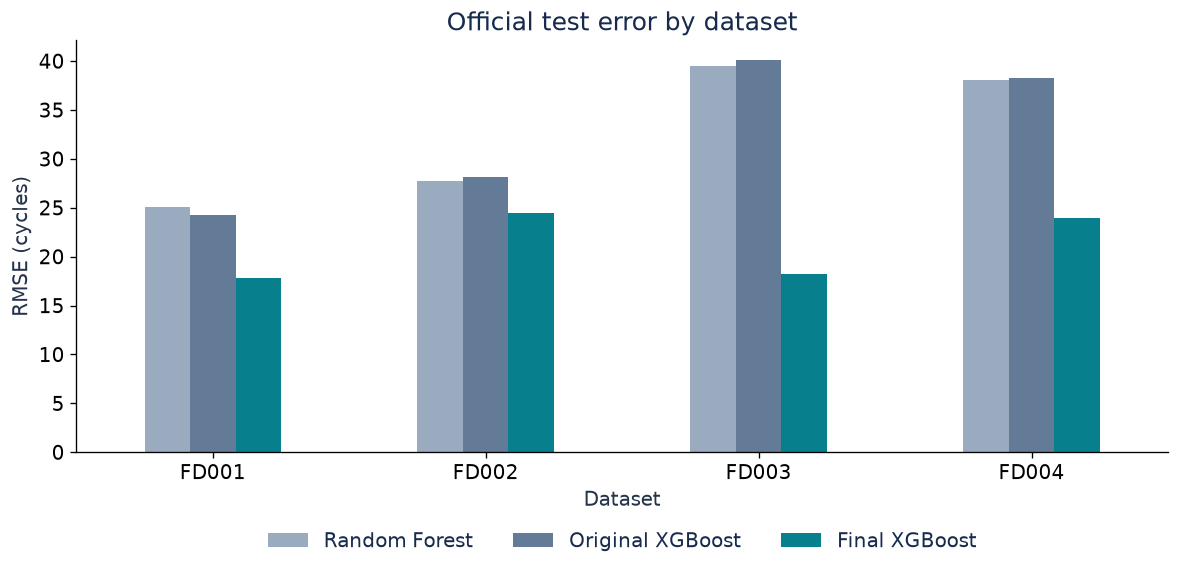

,Random Forest,Original XGBoost,Final XGBoost
FD001,25.06,24.28,17.84
FD002,27.71,28.19,24.47
FD003,39.54,40.11,18.28
FD004,38.02,38.30,23.91


In [6]:
fixed=metrics[metrics.threshold.eq(30)]
selected=fixed[fixed.model.eq('selected') & fixed.dataset.eq('ALL')].iloc[0]
prior=fixed[fixed.model.eq('Random forest') & fixed.dataset.eq('ALL')].iloc[0]
assert np.isclose(selected.RMSE,22.6336838386522)
assert np.isclose(prior.RMSE,33.143425)
lookup={'Random forest':'Random Forest','XGBoost':'Original XGBoost','selected':'Final XGBoost'}
chart=fixed[fixed.dataset.ne('ALL') & fixed.model.isin(lookup)].copy()
chart['Model']=chart.model.map(lookup)
chart=chart.pivot(index='dataset',columns='Model',values='RMSE')[['Random Forest','Original XGBoost','Final XGBoost']]
ax=chart.plot.bar(rot=0,color=[COLORS[c] for c in chart],figsize=(10,5))
ax.set(xlabel='Dataset',ylabel='RMSE (cycles)',title='Official test error by dataset')
ax.legend(title=None,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=3,frameon=False)
plt.tight_layout()
plt.show()
display(chart.rename_axis(index=None,columns=None).round(2))

**Interpretation:** the combined pipeline improves every test subset, with the
largest absolute reduction in FD003. This table cannot attribute the gain to one
sensor, one feature or normalization alone.

The final errors are similar within operating-condition groups: single-condition
FD001/FD003 achieve 17.84/18.28 cycles, versus 24.47/23.91 for six-condition
FD002/FD004. The original errors instead separated more strongly by fault-mode
count. This four-dataset pattern is descriptive; it does not establish causation.

## 7. Maintenance alerts: make the precision–recall tradeoff explicit

The event remains **actual RUL ≤30 cycles**. The alert threshold applies to the
model's prediction, so changing it does not alter predicted RUL or RMSE.

A threshold of **34.44 predicted cycles** was chosen from out-of-fold development
predictions to target at least 90% recall. On the official test it catches **149 of
159 near-failure engines**, with **12 false alerts**.

In [7]:
alerts=metrics[metrics.model.isin(['XGBoost','selected']) & metrics.dataset.eq('ALL')].copy()
alerts['Model']=alerts.model.map({'XGBoost':'Original XGBoost','selected':'Final XGBoost'})
alerts=alerts.sort_values(['model','threshold'])
view=alerts[['Model','threshold','precision','recall','TP','FN','FP']].rename(columns={
 'threshold':'Alert threshold','precision':'Precision','recall':'Recall','TP':'Caught','FN':'Missed','FP':'False alerts'})
view['Precision']=view.Precision.map(lambda x:f'{x:.1%}')
view['Recall']=view.Recall.map(lambda x:f'{x:.1%}')
view['Alert threshold']=view['Alert threshold'].round(2)
display(view.set_index('Model').rename_axis(index=None,columns=None))

,Alert threshold,Precision,Recall,Caught,Missed,False alerts
Original XGBoost,30.00,94.9%,81.8%,130,29,7
Final XGBoost,30.00,94.7%,89.9%,143,16,8
Final XGBoost,34.44,92.5%,93.7%,149,10,12


At threshold 30, the final model catches 143 engines and raises eight false alerts.
Calibration catches six additional engines at the cost of four additional false
alerts. Audit-primary recall was 90%; test recall is 93.7%. Neither is a guarantee
for another fleet or operating policy.

NASA's asymmetric error score is also reported in the experiment tables. It
penalizes overestimation more heavily, but does not replace inspection costs or
a validated maintenance policy.

## 8. The result has a boundary

The untouched 142-engine audit confirms a benefit in the planning window:
**33.01 → 25.67 cycles RMSE**. A paired engine-bootstrap 95% interval puts the
improvement at **4.34–10.59 cycles**.

**Earlier-life-inclusive performance worsens: 39.80 → 43.32 cycles RMSE.**
The training cap encourages predictions to level off near 150 cycles, so the
model should not be presented as a precise estimator of much longer remaining life.

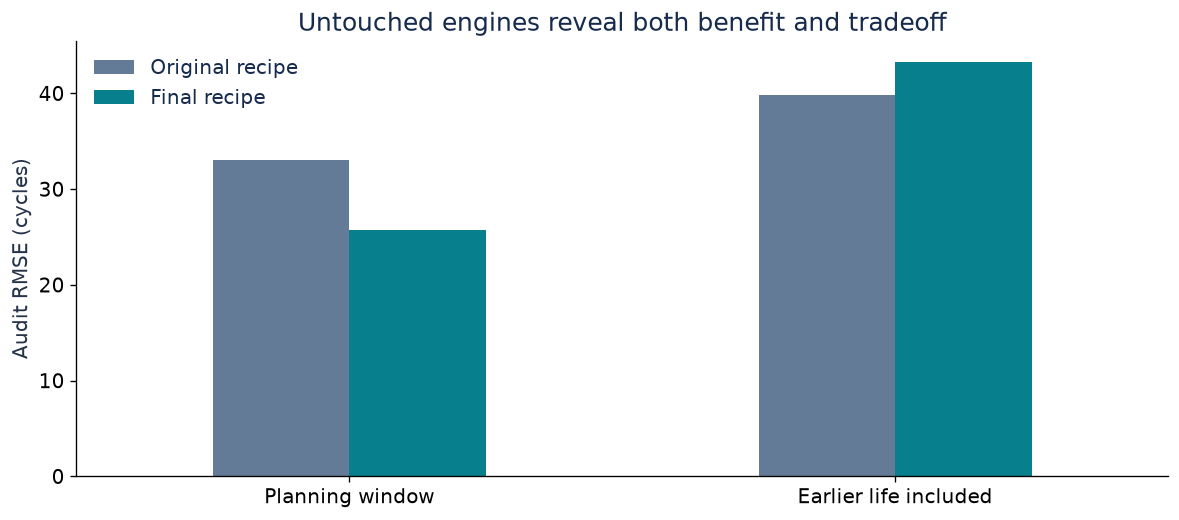

In [8]:
shown=audit[audit.threshold.eq(30)].pivot(index='protocol',columns='model',values='RMSE')
shown=shown.reindex(['primary','broad']).rename(index={'primary':'Planning window','broad':'Earlier life included'},columns={'reference':'Original recipe','selected':'Final recipe'})
ax=shown.plot.bar(rot=0,color=['#637b96','#087f8c'],figsize=(10,4.5))
ax.set(xlabel='',ylabel='Audit RMSE (cycles)',title='Untouched engines reveal both benefit and tradeoff')
ax.legend(title=None,frameon=False)
plt.tight_layout()
plt.show()

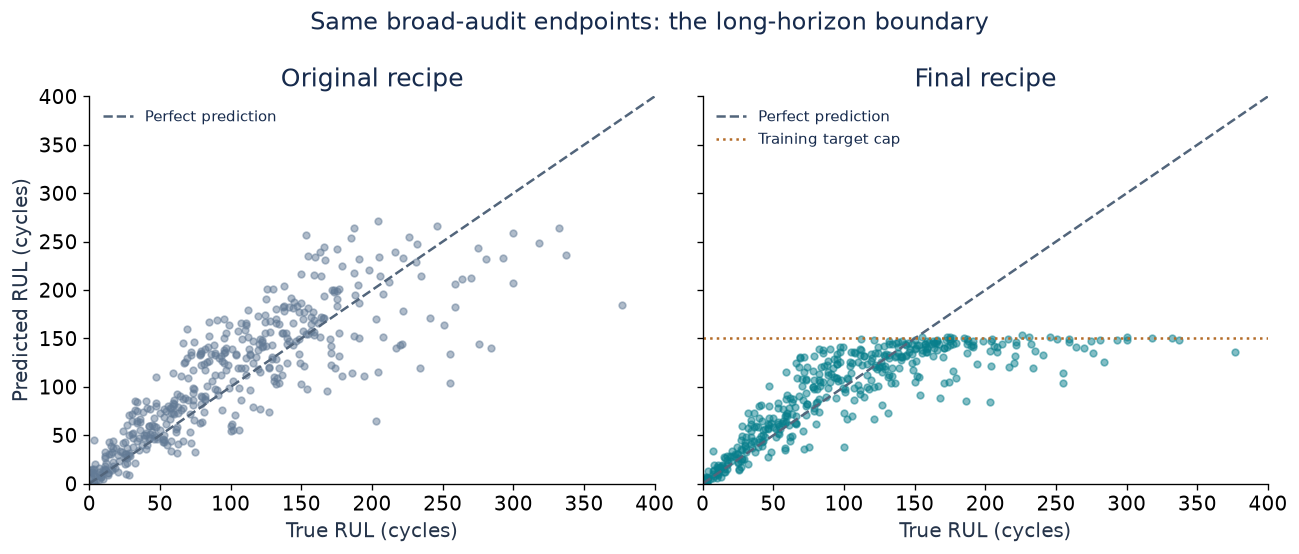

In [9]:
pred=pd.read_csv(EXP/'audit_predictions.csv')
broad=pred[pred.protocol.eq('broad')]
fig,axes=plt.subplots(1,2,figsize=(11,4.7),sharex=True,sharey=True)
limit=np.ceil(max(broad.actual_RUL.max(),broad.predicted_RUL.max())/50)*50
for ax,model,label,color in zip(axes,['reference','selected'],['Original recipe','Final recipe'],['#637b96','#087f8c']):
    points=broad[broad.model.eq(model)]
    ax.scatter(points.actual_RUL,points.predicted_RUL,s=16,alpha=.5,color=color)
    ax.plot([0,limit],[0,limit],color='#52657b',linestyle='--',label='Perfect prediction')
    if model=='selected': ax.axhline(150,color='#b46c29',linestyle=':',label='Training target cap')
    ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='True RUL (cycles)',title=label)
    ax.legend(fontsize=9,frameon=False)
axes[0].set_ylabel('Predicted RUL (cycles)')
fig.suptitle('Same broad-audit endpoints: the long-horizon boundary')
fig.tight_layout()
plt.show()

The dotted line marks the training target cap, not a hard prediction constraint.
Both panels use the same 426 endpoints from the original 142-engine audit.

## 9. Does the gain survive different splits and windows?

We retrained both frozen recipes locally on **five stratified engine splits**:
567 fitting engines and 142 held-out engines per split. Each scenario uses three
fixed observation points per engine, with at least 20 observed cycles.
Model settings and the calibrated threshold stayed fixed.

**All five splits improve for each 100–250-cycle planning window.** Broad lifetime
coverage worsens in four of five splits. For the 200-cycle window, RMSE improves
by **8.31–12.14 cycles** across these splits.

These are sensitivity checks, not five independent blind replications: held-out
sets overlap, and some engines informed the earlier model selection. New endpoint
sampling also means these numbers need not equal the original audit.

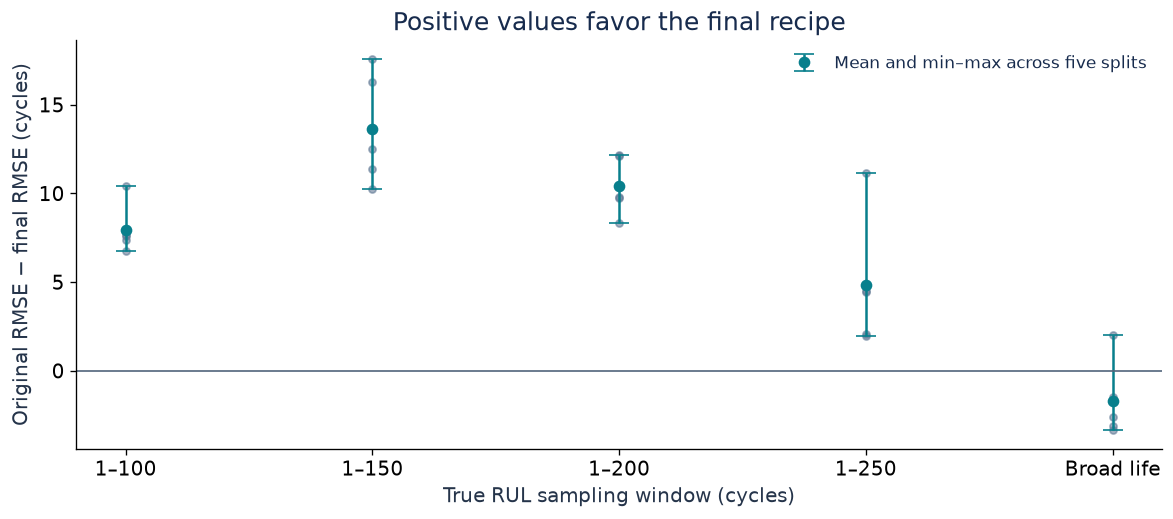

In [10]:
checks=pd.read_csv(ROB/'split_metrics.csv')
gains=checks.pivot(index=['seed','scenario'],columns='model',values='RMSE')
gains['gain']=gains['Original recipe']-gains['Final recipe']
order=['RUL_1_100','RUL_1_150','RUL_1_200','RUL_1_250','broad']
summary=gains.groupby('scenario')['gain'].agg(['min','mean','max']).reindex(order)
fig,ax=plt.subplots(figsize=(10,4.5))
x=np.arange(len(order))
ax.errorbar(x,summary['mean'],yerr=[summary['mean']-summary['min'],summary['max']-summary['mean']],fmt='o',capsize=6,color='#087f8c',label='Mean and min–max across five splits')
for seed,group in gains.reset_index().groupby('seed'):
    ax.scatter(x,group.set_index('scenario').loc[order,'gain'],s=18,color='#637b96',alpha=.6)
ax.axhline(0,color='#52657b',linewidth=1)
ax.set(xticks=x,xticklabels=['1–100','1–150','1–200','1–250','Broad life'],xlabel='True RUL sampling window (cycles)',ylabel='Original RMSE − final RMSE (cycles)',title='Positive values favor the final recipe')
ax.legend(frameon=False,fontsize=10)
fig.tight_layout()
plt.show()

Bars show a descriptive range across splits, **not a confidence interval**.
The broad scenario samples observed cycles uniformly across each available life.

## 10. How uncertain are the alert results?

The same 707 official test endpoints support this comparison. Intervals are
95% Wilson intervals for recall among actual events and precision among alerts.
They describe sampling uncertainty conditional on the fixed models and rule;
they exclude selection uncertainty, refitting and changes in fleet conditions.

In [11]:
intervals=pd.read_csv(ROB/'test_alert_intervals.csv')
shown=intervals[intervals.dataset.eq('ALL')].copy()
shown['Estimate [95% interval]']=shown.apply(lambda row:f'{row.estimate:.1%} [{row.lower95:.1%}, {row.upper95:.1%}]',axis=1)
shown['Policy']=shown.model+' / '+shown.threshold.map(lambda value:f'{value:.2f}')
display(shown.pivot(index='Policy',columns='metric',values='Estimate [95% interval]').rename_axis(index=None,columns=None))

,precision,recall
"Final, calibrated alert / 34.44","92.5% [87.4%, 95.7%]","93.7% [88.8%, 96.5%]"
"Final, fixed alert / 30.00","94.7% [89.9%, 97.3%]","89.9% [84.3%, 93.7%]"
Original XGBoost / 30.00,"94.9% [89.8%, 97.5%]","81.8% [75.0%, 87.0%]"


Calibrated test recall is **93.7% [88.8%, 96.5%]**, and precision is
**92.5% [87.4%, 95.7%]**. The data do not guarantee at least 90% recall.

Separately, on the original audit-primary population, calibrated recall is
**90.0% [83.3%, 95.6%]** and precision **89.0% [82.2%, 95.1%]** using 2,000
whole-engine bootstrap draws. That resamples engines with all three endpoints
together; these audit results are not interchangeable with the official test.

## 11. When does the first alert arrive?

We replayed full held-out engine histories in each of the five splits, monitoring
from **cycle 20 to the cycle before failure**. A first alert at 32 cycles remaining
is slightly ahead of the illustrative 30-cycle window; it should not be equated
with a warning more than 60 cycles early.

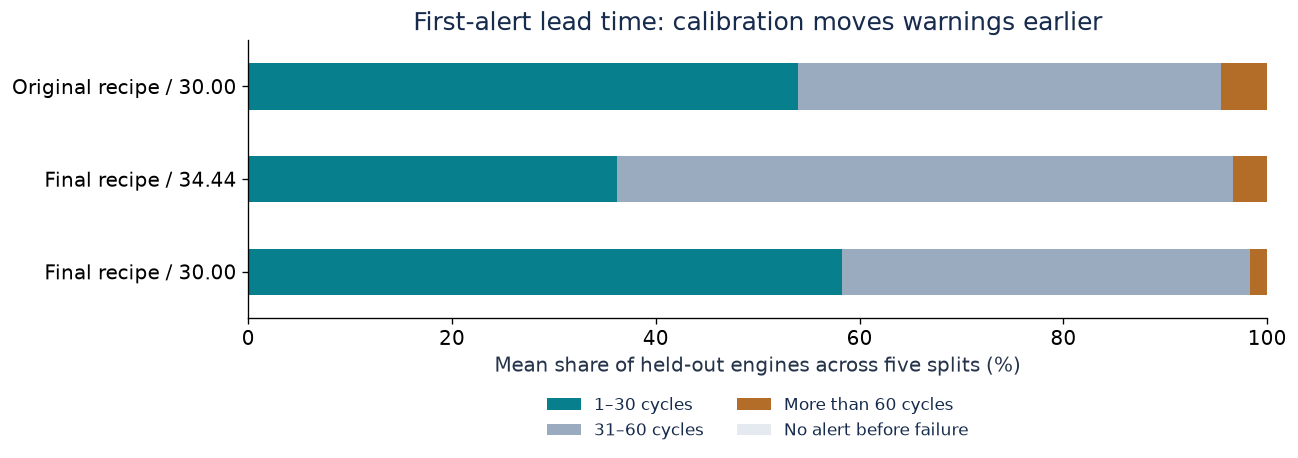

,Minimum split median (cycles),Maximum split median (cycles)
Final recipe / 30.00,27.5,30.0
Final recipe / 34.44,32.0,34.0
Original recipe / 30.00,28.0,32.0


In [12]:
trajectory=pd.read_csv(ROB/'trajectory_summary.csv')
trajectory['Policy']=trajectory.model+' / '+trajectory.threshold.map(lambda value:f'{value:.2f}')
columns=['timely_first_alert_fraction','first_alert_31_60_fraction','first_alert_over60_fraction','no_alert_fraction']
shares=trajectory.groupby('Policy')[columns].mean()
shares.columns=['1–30 cycles','31–60 cycles','More than 60 cycles','No alert before failure']
ax=(shares*100).plot.barh(stacked=True,color=['#087f8c','#9aabc0','#b46c29','#e5eaf0'],figsize=(11,4.2))
ax.set(xlabel='Mean share of held-out engines across five splits (%)',ylabel='',xlim=(0,100),title='First-alert lead time: calibration moves warnings earlier')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.23),ncol=2,frameon=False,fontsize=10)
plt.tight_layout()
plt.show()
timing=trajectory.groupby('Policy').median_first_alert_lead.agg(['min','max'])
timing.columns=['Minimum split median (cycles)','Maximum split median (cycles)']
display(timing.rename_axis(index=None,columns=None))

The calibrated rule's median first alert arrives **32–34 cycles before failure**
across splits, versus **27.5–30 cycles** for the final model at threshold 30.
All held-out histories have at least one alert within their last 30 cycles before
failure. This repeated opportunity to alert differs from one-endpoint recall;
it is not a reliability guarantee.

This is a **passive replay**: an alert does not trigger a modeled inspection or
change the subsequent trajectory. Repeated warnings and inspection costs still
need an intervention policy. Engines recur across splits, so the chart averages
split proportions rather than claiming 710 independent engines.

## 12. Do sequence models improve this comparison?

We trained a compact **LSTM** and **TCN** locally using 30-cycle sensor histories,
two random seeds and the same three development-engine folds and evaluation
endpoints as XGBoost. Each outer training fold has a separate inner engine split
for early stopping; the network is then refitted on all outer fitting engines
before scoring the outer validation engines.

The table reports **development CV**, not the official test. Targets are capped
only during training; evaluation labels remain uncapped. Both primary and broad
protocols use 1,701 endpoints from the same 567 development engines per seed.

In [13]:
seq=pd.read_csv(ROOT/'outputs/sequences/metrics.csv')
reference=pd.read_csv(ROOT/'outputs/sequences/xgboost_reference.csv').set_index('protocol')
rows=[{'Model':'XGBoost','Seed':'42 (existing)','Primary RMSE':reference.loc['primary','RMSE'],'Broad RMSE':reference.loc['broad','RMSE']}]
for (model,seed),group in seq.groupby(['model','seed']):
    group=group.set_index('protocol')
    rows.append({'Model':model,'Seed':str(seed),'Primary RMSE':group.loc['primary','RMSE'],'Broad RMSE':group.loc['broad','RMSE']})
display(pd.DataFrame(rows).set_index(['Model','Seed']).round(2).rename_axis(index=[None,None],columns=None))

Primary RMSE  Broad RMSE
XGBoost 42 (existing)         25.93       45.32
LSTM    42                    26.43       45.69
        73                    26.63       45.81
TCN     42                    26.02       45.75
        73                    26.19       45.84

**Initial result:** neither tested sequence configuration improves pooled primary RMSE,
but all paired 95% intervals include zero; this does not establish a clear
accuracy advantage for either family. At the same threshold of 30, TCN recall
is **62.8–70.3%**, versus **81.2%** for XGBoost, with higher precision. Similar
RMSE does not imply equivalent alert behavior. No neural threshold was calibrated in this initial comparison; the follow-up below tests calibration separately.

This is a bounded comparison of specific model configurations, not a ranking
of all tree and neural methods. XGBoost was tuned in earlier experiments; the
networks received one fixed architecture each and a maximum of 20 inner-training
epochs. Two random seeds are not independent samples of new engines. The
existing final XGBoost model and its official test predictions remain unchanged.

[Sequence methods](outputs/sequences/METHODS.md) include architecture details,
[paired comparisons](outputs/sequences/paired_comparison.csv),
[training curves](outputs/sequences/learning_curves.csv), and
[matched-protocol training/validation errors](outputs/sequences/generalization_gaps.csv).

### Follow-up: training budget, history length and alert calibration

We then tested **30- and 50-cycle histories**, up to **60 training epochs**, and
**three seeds per window**. The same architecture, engine folds and endpoints
were retained. A contemporaneous 20-epoch reference isolates the budget change;
early stopping can still end a run before either maximum.

These are development-CV results on the same 567 engines. The ranges below
show variation across seeds, not confidence intervals. The comparison remains
a bounded follow-up on an already-studied benchmark.

In [14]:
followup=pd.read_csv(ROOT/'outputs/tcn_followup/metrics.csv')
fixed=followup[followup.rule.eq('fixed_30')]
reference=comparison[comparison.candidate.eq('tuned_d6_n800')].set_index('protocol')
rows=[{'History / max epochs':'XGBoost reference',
       'Primary RMSE':f"{reference.loc['primary','RMSE']:.2f}",
       'Broad RMSE':f"{reference.loc['broad','RMSE']:.2f}"}]
for (window,budget),g in fixed.groupby(['window','budget']):
    primary=g[g.protocol.eq('primary')].RMSE
    broad=g[g.protocol.eq('broad')].RMSE
    rows.append({'History / max epochs':f'TCN {window} / {budget}',
                 'Primary RMSE':f'{primary.min():.2f}–{primary.max():.2f}',
                 'Broad RMSE':f'{broad.min():.2f}–{broad.max():.2f}'})
display(pd.DataFrame(rows).set_index('History / max epochs').rename_axis(index=None))

,Primary RMSE,Broad RMSE
XGBoost reference,25.93,45.32
TCN 30 / 20,25.80–26.05,45.25–45.73
TCN 30 / 60,25.97–26.00,45.47–45.84
TCN 50 / 60,23.59–24.13,43.75–43.96


For each fold, the alert threshold was selected to reach at least 90% recall
on the **inner stopping engines**, then transferred to the refitted model and
scored on **separate outer engines**. Refitting and sampling variation can change
calibration; outer recall is not guaranteed to reach the inner target.

The following table uses the 60-epoch budget. Calibration changes the alert rule,
not the RUL predictions or RMSE. Thresholds vary by fold and seed.

In [15]:
rows=[]
for (window,rule),g in followup[followup.protocol.eq('primary') & followup.budget.eq(60)].groupby(['window','rule']):
    rows.append({'History':window,'Alert rule':{'fixed_30':'Fixed 30','inner_calibrated':'Inner-calibrated'}[rule],
                 'Recall':f'{g.recall.min():.1%}–{g.recall.max():.1%}',
                 'Precision':f'{g.precision.min():.1%}–{g.precision.max():.1%}'})
display(pd.DataFrame(rows).set_index(['History','Alert rule']).rename_axis(index=[None,None]))

Recall    Precision
30 Fixed 30          63.1%–74.7%  97.8%–99.5%
   Inner-calibrated  89.8%–93.9%  86.3%–88.4%
50 Fixed 30          75.1%–81.2%  97.8%–98.3%
   Inner-calibrated  90.8%–93.5%  90.1%–92.2%

**Finding:** the 50-cycle TCN reaches **23.59–24.13 primary CV RMSE**, a
**7–9% reduction** from the XGBoost reference. All three paired 95% intervals
favor TCN on these endpoints. Every matched fold/seed improves over the
30-cycle TCN. More training alone at 30 cycles does not consistently help;
only two of nine runs select later epochs.

Calibration raises 50-cycle TCN recall to **90.8–93.5%**, while precision falls
to **90.1–92.2%**. False alerts increase from 4–5 to 23–30 per 1,701 primary
endpoints. These are snapshot alerts, not unique-engine or first-alert counts.
One individual fold/seed reaches only 86.7% recall; the 90% inner target is
not a guarantee on separate engines.

**Decision:** keep the 50-cycle TCN as the stronger development candidate for
independent validation. These are repeated development comparisons; the paired
intervals condition on fitted models and are not adjusted for multiple tests.
The original XGBoost test headline and final model remain unchanged.

[Follow-up methods and interpretation](outputs/tcn_followup/METHODS.md),
[paired RMSE comparisons](outputs/tcn_followup/paired_comparisons.csv), and
[alert uncertainty intervals](outputs/tcn_followup/alert_intervals.csv) retain
the detailed evidence. No new audit or official-test evaluation was performed.


### Overfitting: a measurable gap, with held-out gains

We reloaded the saved models and compared fitting and held-out engines using
identical uncapped scoring, causal histories and endpoint rules. The table shows
the 50-cycle TCN; each row is one random seed and pools squared errors across the same three folds.
Training predictions include each engine in two fitting folds, while validation
uses each engine once. These are descriptive gaps, not confidence intervals.

In [16]:
gaps=pd.read_csv(ROOT/'outputs/tcn_followup/generalization_summary.csv')
table=gaps[gaps.window.eq(50) & gaps.protocol.eq('primary') & gaps.subset.eq('all')]
table=table[['seed','training_RMSE','validation_RMSE','gap']].set_index('seed')
display(table.rename(columns={'training_RMSE':'Training RMSE','validation_RMSE':'Validation RMSE','gap':'Gap'}).rename_axis(index=None).round(2))

,Training RMSE,Validation RMSE,Gap
42,19.13,23.69,4.56
73,19.68,23.59,3.91
101,18.66,24.13,5.46


**Interpretation:** the **3.91–5.46-cycle gap** supports concern about
overfitting. The 50-cycle model nevertheless improves held-out RMSE across all
three seeds. The gap persists below the 150-cycle cap; near failure (true RUL
≤30), it is smaller at 0.21–1.55 cycles. Early stopping limits continued fitting
but does not remove the gap.

Engine separation, saved-prediction reproduction and future/target isolation
checks passed. Repeated use of these development folds still creates selection
risk; this is not proof of generalization to new fleets. See the
[overfitting methods and subgroup results](outputs/tcn_followup/METHODS.md).

## 13. What we can defend—and what comes next

**Supported:** lower planning-window error across the tested splits and horizons,
an explicit sensor ablation, uncertainty estimates for snapshot alerts, and a
measured first-alert tradeoff on simulated held-out histories. A 50-cycle TCN
also improves error in the follow-up development comparison.

**Not established:** a globally optimal model, real-fleet reliability or savings,
accurate long-horizon RUL, a guaranteed recall target, or a meaningful performance
difference between the 14- and 17-sensor variants.

The next substantive step is independent validation of the frozen 50-cycle TCN
recipe, ideally on an external dataset, and an explicit inspection
policy with costs and intervention outcomes. A new external dataset would
provide stronger evidence than further tuning on this already-observed benchmark.

## Appendix · Evidence and reproduction

- [Baseline notebook](baseline.ipynb): data exploration and original model comparison.
- [Experiment notebook](experiments.ipynb): all 21 configurations, audit and test results.
- [Methods](outputs/experiments/METHODS.md): endpoint sampling, selection and limitations.
- [Robustness methods](outputs/robustness/METHODS.md), [split metrics](outputs/robustness/split_metrics.csv),
  [alert intervals](outputs/robustness/test_alert_intervals.csv) and
  [first-alert events](outputs/robustness/engine_alert_events.csv).
- [Sequence comparison](outputs/sequences/METHODS.md) and [TCN follow-up](outputs/tcn_followup/METHODS.md): development results, training budgets and alert calibration.
- [Sensor audit](outputs/presentation/sensor_audit.csv) and
  [sensor ablation](outputs/presentation/sensor_ablation.csv): all channels and matched CV results.
- [Reproduction guide](docs/REPRODUCING.md): regenerate the trained model and
  large prediction exports, which are excluded from Git. Compact report inputs remain included.

This notebook reads saved results; opening or executing it does not train models.
All model fitting was performed locally. Training scripts and timestamped logs
remain in the project. See [README.md](README.md) for reproduction commands.

Method reference: [Saxena et al., NASA scoring function, equation 9](https://ntrs.nasa.gov/api/citations/20090029214/downloads/20090029214.pdf).

Course structure: business understanding → data checks and EDA → feature engineering
→ modeling and validation → evaluation and decision thresholds.